Objectif : Améliorer la précision du PINN pour les faibles viscosités

Sources : [Surrogate modeling for fluid flows based on physics-constrained deep
learning without simulation data](https://reader.elsevier.com/reader/sd/pii/S004578251930622X?token=AA07BED4AF49DDD062CCC26F45494E78C0D744A133E1B0A6547E66F5319F4FADC2A53C683A39F7C39B16A0A2F68ABBCD&originRegion=eu-west-1&originCreation=20220228112931)

# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
import copy as cp
import scipy.sparse.linalg as linalg
import matplotlib.pyplot as plt
from time import time
import scipy.optimize

gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
  tf.config.experimental.set_memory_growth(gpu, True)

# Paramètres

In [2]:
# Set data type
DTYPE='float32'
tf.keras.backend.set_floatx(DTYPE)

# Set constants
pi = tf.constant(np.pi, dtype=DTYPE)
viscosity = tf.constant(1e-3, dtype=DTYPE)

# Set boundary
tmin = 0.
tmax = 1.
xmin = -1.
xmax = 1.

# Lower bounds
lb = tf.constant([tmin, xmin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax], dtype=DTYPE)

# Define initial condition
def fun_u_0(x):
    return -tf.sin(pi * x)

# Define boundary condition
def fun_u_b(t, x):
    n = x.shape[0]
    return tf.zeros((n,1), dtype=DTYPE)

## Data generation

In [5]:
def gen_train_data(N_r = 10_000):

  # Set random seed for reproducible results
  tf.random.set_seed(0)

  # Draw uniformly sampled collocation points
  t_r = tf.random.uniform((N_r,1), lb[0], ub[0], dtype=DTYPE)
  x_r = tf.random.uniform((N_r,1), lb[1], ub[1], dtype=DTYPE)
  X_r = tf.concat([t_r, x_r], axis=1)

  return X_r

def plot_train_data(X_r):

    t_r = X_r[:,0]
    x_r = X_r[:,1]

    fig = plt.figure(figsize=(9,6))
    plt.scatter(t_r, x_r, c='r', marker='.', alpha=0.1)
    plt.xlabel('$t$')
    plt.ylabel('$x$')

    plt.title('Positions of collocation points ');

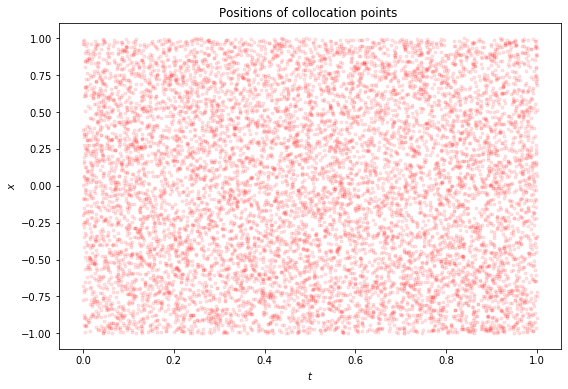

In [8]:
X_r = gen_train_data(10_000)
plot_train_data(X_r)

## PINN model

In [10]:
class PhysicsInformedNN(tf.keras.Model):
    """ Set basic architecture of the PINN model."""

    def __init__(self, lb, ub, 
            output_dim=1,
            num_hidden_layers=8, 
            num_neurons_per_layer=20,
            activation='tanh',
            kernel_initializer='glorot_normal',
            **kwargs):
        super().__init__(**kwargs)

        self.num_hidden_layers = num_hidden_layers
        self.output_dim = output_dim
        self.lb = lb
        self.ub = ub
        
        # Define NN architecture
        self.scale = tf.keras.layers.Lambda(
            lambda x: 2.0*(x - lb)/(ub - lb) - 1.0)
        self.hidden = [tf.keras.layers.Dense(num_neurons_per_layer,
                             activation=tf.keras.activations.get(activation),
                             kernel_initializer=kernel_initializer)
                           for _ in range(self.num_hidden_layers)]
        self.out = tf.keras.layers.Dense(output_dim)

    def call_before(self,X):
        """Forward-pass through neural network."""
        
        Z = self.scale(X)
        for i in range(self.num_hidden_layers):
            Z = self.hidden[i](Z)
        Y = self.out(Z)
        
        return Y
        
        
    def call(self, X):
        """Call with imposed IC/BC"""
        
        t = X[:,0:1]
        x = X[:,1:2]
        Y = self.call_before(X)
        
        tanh_t = tf.tanh(t)
        
        return (1-tanh_t)*fun_u_0(x) + (x+1)*(1-x)*tanh_t*Y

In [25]:
class PINNSolver():
    def __init__(self, model, X_r):
        self.model = model
        
        # Store collocation points
        self.t = X_r[:,0:1]
        self.x = X_r[:,1:2]
        
        # Initialize history of losses and global iteration counter
        self.hist = []
        self.iter = 0
        
    def get_r(self):
        
        with tf.GradientTape(persistent=True) as tape:
            # Watch variables representing t and x during this GradientTape
            tape.watch(self.t)
            tape.watch(self.x)
            
            # Compute current values u(t,x)
            u = self.model(tf.stack([self.t[:,0], self.x[:,0]], axis=1))
            u2 = tf.square(u)
            
            u_x = tape.gradient(u, self.x)
            
        u_t = tape.gradient(u, self.t)
        u_xx = tape.gradient(u_x, self.x)
        u2_x = tape.gradient(u2, self.x)

        del tape
        
        return u_t + u2_x/2. - viscosity * u_xx
    
    def loss_fn(self):
        
        # Compute phi_r
        r = self.get_r()
        phi_r = tf.reduce_mean(tf.square(r))

        # Initialize loss
        loss = phi_r
        
        return loss
    
    def get_grad(self):
        with tf.GradientTape(persistent=True) as tape:
            # This tape is for derivatives with
            # respect to trainable variables
            tape.watch(self.model.trainable_variables)
            loss = self.loss_fn()
            
        g = tape.gradient(loss, self.model.trainable_variables)
        del tape
        
        return loss, g
    
    def solve_with_TFoptimizer(self, optimizer, N):
        """This method performs a gradient descent type optimization."""
        
        @tf.function
        def train_step():
            loss, grad_theta = self.get_grad()
            
            # Perform gradient descent step
            optimizer.apply_gradients(zip(grad_theta, self.model.trainable_variables))
            return loss
        
        for i in range(N):
            
            loss = train_step()
            
            self.current_loss = loss.numpy()
            self.callback()

    def solve_with_ScipyOptimizer(self, method='L-BFGS-B'):
        
        def get_weight_tensor():
            """Function to return current variables of the model
            as 1d tensor as well as corresponding shapes as lists."""
            
            weight_list = []
            shape_list = []
            
            # Loop over all variables, i.e. weight matrices, bias vectors and unknown parameters
            for v in self.model.variables:
                shape_list.append(v.shape)
                weight_list.extend(v.numpy().flatten())
                
            weight_list = tf.convert_to_tensor(weight_list)
            return weight_list, shape_list

        x0, shape_list = get_weight_tensor()
        
        def set_weight_tensor(weight_list):
            """Function which sets list of weights
            to variables in the model."""
            idx = 0
            for v in self.model.variables:
                vs = v.shape
                
                # Weight matrices
                if len(vs) == 2:  
                    sw = vs[0]*vs[1]
                    new_val = tf.reshape(weight_list[idx:idx+sw],(vs[0],vs[1]))
                    idx += sw
                
                # Bias vectors
                elif len(vs) == 1:
                    new_val = weight_list[idx:idx+vs[0]]
                    idx += vs[0]
                    
                # Variables (in case of parameter identification setting)
                elif len(vs) == 0:
                    new_val = weight_list[idx]
                    idx += 1
                    
                # Assign variables (Casting necessary since scipy requires float64 type)
                v.assign(tf.cast(new_val, DTYPE))
        
        def get_loss_and_grad(w):
            """Function that provides current loss and gradient
            w.r.t the trainable variables as vector. This is mandatory
            for the LBFGS minimizer from scipy."""
            
            # Update weights in model
            set_weight_tensor(w)
            # Determine value of \phi and gradient w.r.t. \theta at w
            loss, grad = self.get_grad()
            
            # Store current loss for callback function            
            loss = loss.numpy().astype(np.float64)
            self.current_loss = loss            
            
            # Flatten gradient
            grad_flat = []
            for g in grad:
                grad_flat.extend(g.numpy().flatten())
            
            # Gradient list to array
            grad_flat = np.array(grad_flat,dtype=np.float64)
            
            # Return value and gradient of \phi as tuple
            return loss, grad_flat
        
        scipy.optimize.minimize(fun=get_loss_and_grad,
                                       x0=x0,
                                       jac=True,
                                       method=method,
                                       callback=self.callback,
                                       options={'maxiter': 2000,
                                                'maxfun': 50000,
                                                'maxcor': 50,
                                                'maxls': 50,
                                                'ftol': 1.0*np.finfo(float).eps})
        
    def callback(self, xr=None):
        
        if self.iter % 100 == 0:
            print('Iteration {:05d}: loss = {:10.8e}'.format(self.iter,self.current_loss))
        self.hist.append(self.current_loss)
        self.iter+=1
        
    def plot_loss_history(self, ax=None):

        if not ax:
            fig = plt.figure(figsize=(7,5))
            ax = fig.add_subplot(111)

        ax.semilogy(range(len(self.hist)), self.hist,'k-', label='Loss')
        ax.set_xlabel('$Iteration$')
        ax.set_ylabel('Loss')

        return ax

In [36]:
model = PhysicsInformedNN(lb, ub, num_hidden_layers=5, num_neurons_per_layer=30, activation='tanh')
#model.build(input_shape=(None,2))

# Initilize PINN solver
solver = PINNSolver(model, X_r)

In [37]:
t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-4,
    decay_steps=1000,
    decay_rate=0.8,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, N=5000)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Iteration 00000: loss = 5.58824182e-01
Iteration 00100: loss = 5.30994713e-01
Iteration 00200: loss = 4.98384774e-01
Iteration 00300: loss = 4.12502259e-01
Iteration 00400: loss = 3.36827040e-01
Iteration 00500: loss = 3.22598398e-01
Iteration 00600: loss = 3.18150520e-01
Iteration 00700: loss = 3.13771278e-01
Iteration 00800: loss = 3.07926565e-01
Iteration 00900: loss = 2.99587339e-01
Iteration 01000: loss = 2.89192080e-01
Iteration 01100: loss = 2.80814350e-01
Iteration 01200: loss = 2.72931159e-01
Iteration 01300: loss = 2.67264754e-01
Iteration 01400: loss = 2.63276815e-01
Iteration 01500: loss = 2.59708732e-01
Iteration 01600: loss = 2.56202728e-01
Iteration 01700: loss = 2.52766430e-01
Iteration 01800: loss = 2.49498457e-01
Iteration 01900: loss = 2.46380568e-01
Iteration 02000: loss = 2.43277267e-01
Iteration 02100: loss = 2.40683451e-01
Iteration 02200: loss = 2.37895653e-01
Iteration 02300: loss = 2.34852239e-01
Iteration 02400: loss = 2.31489792e-01
Iteration 02500: loss = 2

In [43]:
t0 = time()
try: 
  solver.solve_with_ScipyOptimizer()
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Iteration 07000: loss = 1.43081095e-04
Iteration 07100: loss = 1.36136077e-04
Iteration 07200: loss = 1.25686842e-04
Iteration 07300: loss = 1.15090348e-04
Iteration 07400: loss = 1.06342486e-04
Iteration 07500: loss = 1.00691665e-04
Iteration 07600: loss = 9.34719355e-05
Iteration 07700: loss = 8.67797862e-05
Iteration 07800: loss = 7.97308458e-05
Iteration 07900: loss = 7.33999623e-05
Iteration 08000: loss = 6.61221056e-05
Iteration 08100: loss = 6.09763629e-05
Iteration 08200: loss = 5.70119482e-05
Iteration 08300: loss = 5.40721194e-05
Iteration 08400: loss = 5.12945699e-05
Iteration 08500: loss = 4.94581618e-05
Iteration 08600: loss = 4.77294197e-05
Iteration 08700: loss = 4.56925518e-05
Iteration 08800: loss = 4.43409517e-05
Iteration 08900: loss = 4.30533655e-05

Training time: 171.32051730155945 seconds


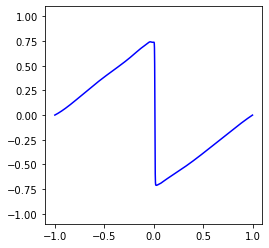

In [39]:
N = 1000
T =  1.0 * np.ones(N+1)
xspace = np.linspace(lb[1], ub[1], N + 1)
nuspace = 0.25 * np.ones(N+1)
Xgrid = np.vstack([T.flatten(),xspace.flatten()]).T
upred = model(tf.cast(Xgrid,DTYPE))

plt.plot(xspace,upred, 'b-');
plt.axis('square')
plt.xlim([-1.1,1.1])
plt.ylim([-1.1,1.1]);

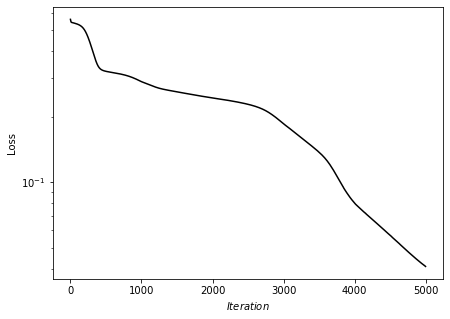

In [40]:
solver.plot_loss_history();

Si le modèle est bien, on le sauvegarde

In [74]:
model.save_weights("oki.h5")

In [31]:
model.load_weights('modelpasmal.h5')

# Vérifications graphiques

In [75]:
from mpl_toolkits.mplot3d import Axes3D

In [76]:
# Set up meshgrid
N = 200
tspace = np.linspace(lb[0], ub[0], N + 1)
xspace = np.linspace(lb[1], ub[1], N + 1)
T, X = np.meshgrid(tspace, xspace)
X_test_grid = np.vstack([T.flatten(),X.flatten()]).T

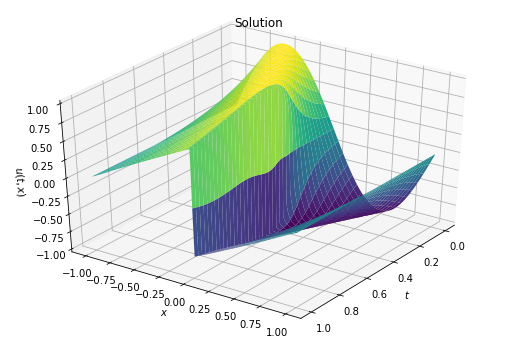

In [77]:
U = model.call(tf.cast(X_test_grid,DTYPE)).numpy().reshape(N+1,N+1)
# Surface plot of u_p
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T, X, U, cmap='viridis');
ax.view_init(35,35)
ax.set_xlabel('$t$')
ax.set_ylabel('$x$')
ax.set_zlabel('$u(t,x)$')
ax.set_title('Solution');

In [28]:
# Classe résolvant Burgers avec des volumes finis 1D (cours P. Helluy)
class EDP:
    def __init__(self,Nx,viscosity, u_0):
      
        self.Nx=Nx  # nb mailles
        self.a=-1.0  # bord gauche du domaine
        self.b=1.0  # bord droit du domaine
        self.viscosity = viscosity
        self.dt=0.0
        self.u_0 = u_0       

        # Pour le maillage Nx mailles et 2 maillages fantome a gauche et droite pour les conditions limites
        self.h=(self.b-self.a)/self.Nx  # pas de maillage
        self.begin = 1  # numéro de la première maille non fantome
        self.end=  self.Nx+1  # numéro de la dernière maille non fantome  
        
        self.nodes=np.linspace(self.a-self.h,self.b+self.h,self.Nx+3) 
        #listes des noeuds: n+1 noeuds et 2 noeuds fantomes
        self.cells=np.linspace(self.a-0.5*self.h,self.b+0.5*self.h,self.Nx+2)
        #listes des centres de mailles: n centres et 2 centres fantomes
        self.rho= np.zeros(self.Nx+2) ## rho sur le maillage + mailles fantomes
    
    #fonction pour initialiser rho
    def init(self):
    
        for i in range(0,len(self.rho)):
            self.rho[i]=self.u_0(self.cells[i])
    
        # on conserve le rho initiale
        self.rho_0=cp.copy(self.rho)

    # flux volumes finis de Lax-Friedrichs
    def flux_hyp_burgers(self,rl,rr):
        center = 0.5*(0.5*rl*rl+0.5*rr*rr)
        vel = max(abs(rl),abs(rr))
        visco=0.5*vel*(rl-rr)
        return center+visco
        
    # flux volumes finis du terme de diffusion
    def flux_diff(self,rl,rr):
        grad = self.viscosity*(rr-rl)/self.h
        return grad
    
    # plot de rho_0 et de rho
    def plot(self):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(self.cells[self.begin:self.end],self.rho_0[self.begin:self.end],'r-')
        axes[1].plot(self.cells[self.begin:self.end],self.rho[self.begin:self.end],'b-')
        
    # condition limite dans les mailles fantomes selon le cas test. A expliquer
    def bc(self):
        self.rho[0]=0
        self.rho[-1]=0
    
    # le terme de diffusion est traité par un schéma implicite en temps
    # le terme de Burgers par un schema implicite
    # Ici on contruit le produit matrice vecteur entre la matrice implicite et un vecteur v
    def matvec_Laplacian(self,v):
        res=np.zeros(self.Nx)
        vl=0.0
        vr=0.0

        res[0]= v[0]-self.dt*self.viscosity/(self.h**2.0)*(vl-2.0*v[0]+v[1])
        for i in range(1,self.Nx-1):
            res[i]= v[i]-self.dt*self.viscosity/(self.h**2.0)*(v[i-1]-2.0*v[i]+v[i+1])
            
        res[-1]= v[-1]-self.dt*self.viscosity/(self.h**2.0)*(v[-2]-2.0*v[-1]+vr)
        return res
        
    # Résolution de l'équation en temps
    # A est un opérateur linéaire associée à la matrice implicite (le produit matrice vecteur)
    # on a pas besoin de construire la matrice pour résoudre un problème avec le gradient conjugé.
    # Il suffit juste de donner ce produit matrice vecteur
    def solve_loc(self,T,flux):
        sol=[]
        nt = 0
        time = 0.0
        rho_temp = np.zeros(self.Nx)
        self.A = linalg.LinearOperator((self.Nx,self.Nx), matvec=self.matvec_Laplacian)
        while time < T:
            # vitesse max de l'équation utile pour CFL
            vmax=max(abs(self.rho[self.begin:self.end]))
            self.dt= 0.5*self.h/vmax
            for i in range(0,self.Nx):
                # calcul des conditions limites dans la mailles fantomes
                self.bc()
                rhol = self.rho[self.begin+i-1]
                rhoc = self.rho[self.begin+i]
                rhor = self.rho[self.begin+i+1]
                # calcul des flux explicite
                fh=flux(rhoc,rhor)-flux(rhol,rhoc)
                # schéma en temps explicite
                rho_temp[i]=rhoc -self.dt/self.h*fh
        
            # schéma en temps implicite en résovlant Arho^{n+1}= Explicit
            self.rho[self.begin:self.end],info=linalg.cg(self.A,rho_temp,x0=None,tol=1e-06,maxiter=200)
            sol.append(cp.copy(self.rho[self.begin:self.end]))
            time=time+self.dt
            nt=nt+1
        return sol
    
    def solve(self,T):
        sol=self.solve_loc(T,self.flux_hyp_burgers)
        return sol
    
def u_0(x):
  return -np.sin(np.pi*x)

In [29]:
all_times = [0.38, 0.5, 1.0]
exact_solutions = []
N = 1000

bg=EDP(N, viscosity.numpy() , u_0)
x = bg.cells[bg.begin:bg.end]


t0 = time()
try: 
    for i_t, end_time in enumerate(all_times):
      bg.init()
      sol=bg.solve(end_time)
      exact_solutions.append(sol[-1])
except:
  pass

print('\nComputing time: {} seconds'.format(time()-t0))



Computing time: 50.12454271316528 seconds


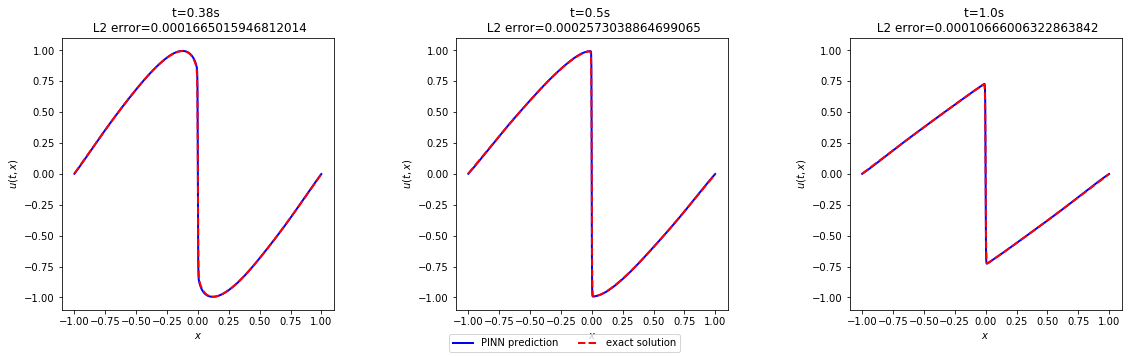

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))

for i_t, end_time in enumerate(all_times):

    exact_sol = exact_solutions[i_t]

    # solution en utilisant le PINN
    T, X = np.meshgrid(end_time, x)
    Xgrid = np.vstack([T.flatten(),X.flatten()]).T
    upred = model(tf.cast(Xgrid,DTYPE))
    upred = tf.reshape(upred, (1,N))[0].numpy()

    # affichage
    erreurL2 = (x[-1]-x[0])/N*np.sum((exact_sol-upred)**2)
    title = "t={}s \n L2 error={}".format(end_time, erreurL2)
    ax[i_t].set_title(title)

    ax[i_t].plot(x, upred, 'b-', linewidth = 2, label="PINN prediction")
    ax[i_t].plot(x, exact_sol, 'r--', linewidth = 2, label="exact solution")

    ax[i_t].set_xlabel('$x$')
    ax[i_t].set_ylabel('$u(t,x)$')    
    ax[i_t].axis('square')
    ax[i_t].set_xlim([-1.1,1.1])
    ax[i_t].set_ylim([-1.1,1.1]);

handles, labels = ax[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4);

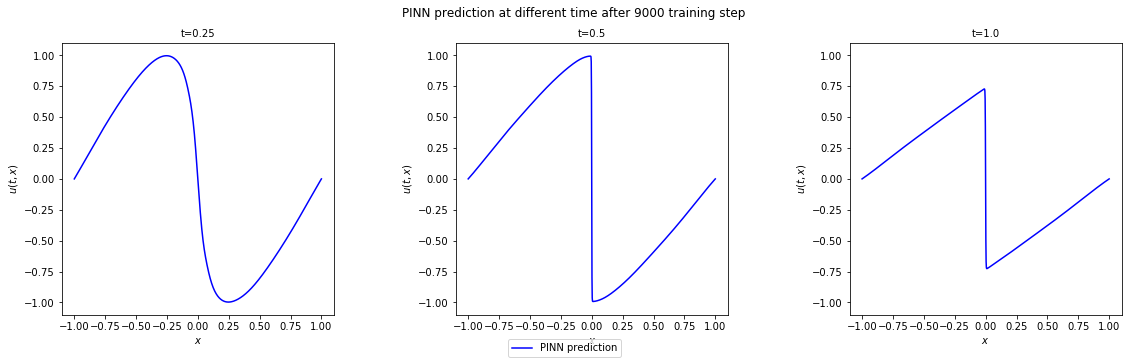

In [82]:
fig, axs = plt.subplots(1, 3, figsize=(20,5))

N=1000
xspace = np.linspace(lb[1], ub[1], N + 1)

all_times=[0.25,0.5,1.0]
for i_t, end_time in enumerate(all_times):

    T, X = np.meshgrid(end_time, xspace)
    Xgrid = np.vstack([T.flatten(),X.flatten()]).T
    upred = model(tf.cast(Xgrid,DTYPE))

    axs[i_t].plot(xspace,upred, 'b-', label="PINN prediction")
    axs[i_t].set_title("t=" + str(end_time), fontsize = 10)
    axs[i_t].set_xlabel('$x$')
    axs[i_t].set_ylabel('$u(t,x)$')    
    axs[i_t].axis('square')
    axs[i_t].set_xlim([-1.1,1.1])
    axs[i_t].set_ylim([-1.1,1.1]);

handles, labels = axs[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4);

plt.suptitle("PINN prediction at different time after {} training step".format(solver.iter));

# Etude du résidu et l'entropie

In [104]:
# Set up meshgrid for plotting
N_test = 200
tspace = np.linspace(lb[0], ub[0], N_test + 1)
xspace = np.linspace(lb[1], ub[1], N_test + 1)
T, X = np.meshgrid(tspace, xspace)
X_test = np.vstack([T.flatten(),X.flatten()]).T

## 1. Le résidu 

le résidu de l'EDP est définit par 

$$
r = \partial_t u + \partial_x u^2/2 - \nu \partial_{xx} u
$$

On souhaite minimiser le résidu de la solution calculée avec le PINN = la solution satisfait bien l'EDP 


In [84]:
def get_residual(model, X_r):
    """fonction qui calcule le résidu"""
    
    # Split t and x to compute partial derivatives
    t, x = X_r[:, 0:1], X_r[:,1:2]
        
    with tf.GradientTape(persistent=True) as tape:
        # Watch variables representing t and x during this GradientTape
        tape.watch(t)
        tape.watch(x)

        # Compute current values u(t,x) and u(t,x)^2
        u = model(tf.stack([t[:,0], x[:,0]], axis=1))
        u2 = tf.square(u)

        u_x = tape.gradient(u, x)

    u_t = tape.gradient(u, t)
    u_xx = tape.gradient(u_x, x)
    u2_x = tape.gradient(u2, x)

    del tape

    return u_t + u2_x/2. - viscosity * u_xx

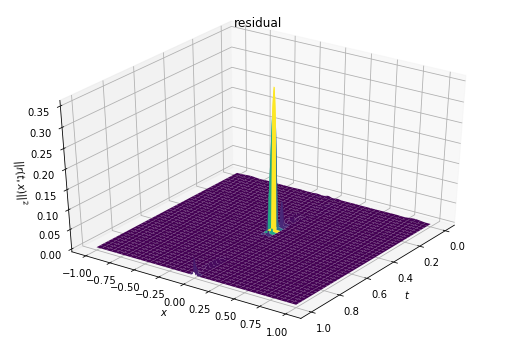

In [85]:
# compute and reshape residual for plotting
Res = get_residual(model, tf.cast(X_test,DTYPE))
R = Res.numpy().reshape(N_test+1,N_test+1)

# Surface plot of residual
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T, X, np.square(R), cmap='viridis');
ax.view_init(35,35)
ax.set_xlabel('$t$')
ax.set_ylabel('$x$')
ax.set_zlabel('$||r(t,x)||^2$')
ax.set_title('residual');

In [86]:
X_test[np.argmax(R)]

array([0.38, 0.  ])

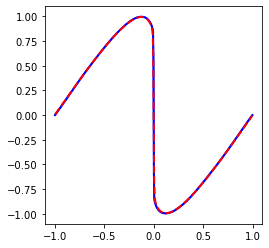

In [35]:
N = 500
tfinal =  0.38 * np.ones(N)
xspace = np.linspace(lb[1], ub[1], N)
Xgrid = np.vstack([tfinal.flatten(),xspace.flatten()]).T
upred = model(tf.cast(Xgrid,DTYPE))

plt.plot(xspace,upred, 'b-');
plt.axis('square')
plt.xlim([-1.1,1.1])
plt.ylim([-1.1,1.1]);


end_time = 0.38
exact_solutions = []
bg=EDP(N, viscosity.numpy() , u_0)
x = bg.cells[bg.begin:bg.end]

bg.init()
sol=bg.solve(end_time)[-1]

plt.plot(x, upred, 'b-', linewidth = 2, label="PINN prediction")
plt.plot(x, sol, 'r--', linewidth = 2, label="exact solution")
        

## 2. L'entropie 

Pour l'équation de Burgers, on doit vérifier que la solution obtenue vérifie
$$
s = \partial_t u^2/2 + \partial_x u^3/3 - \nu \partial_{xx} u^2/2 \leq 0
$$

In [88]:
def get_entropy(model, X_r):
    """fonction qui calcule l'entropie """
    
    with tf.GradientTape(persistent=True) as tape:
        # Split t and x to compute partial derivatives
        t, x = X_r[:, 0:1], X_r[:,1:2]

        # Variables t and x are watched during tape
        # to compute derivatives u_t and u_x
        tape.watch(t)
        tape.watch(x)

        # Determine residual 
        u = model(tf.stack([t[:,0], x[:,0]], axis=1))
        u2 = tf.square(u)
        u3 = u*u2

        # Compute gradient u_x within the GradientTape
        # since we need second derivatives
        u2_x = tape.gradient(u2, x)
            
    eta_t = tape.gradient(u2, t)
    q_x = tape.gradient(u3, x)
    eta_xx = tape.gradient(u2_x, x)

    del tape

    return eta_t/2 +  q_x/3 - viscosity * eta_xx

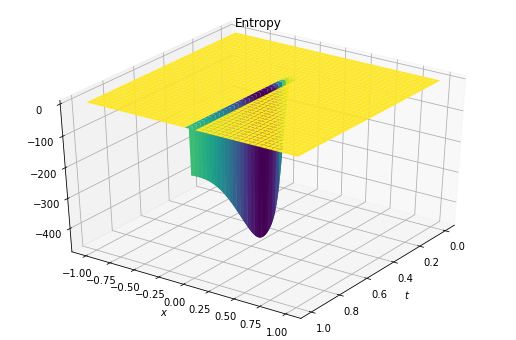

In [89]:
# Compute entropy
Ent = get_entropy(model,tf.cast(X_test,DTYPE))
# Reshape
S = Ent.numpy().reshape(N_test+1,N_test+1)

# Surface plot of entropy
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T, X, S, cmap='viridis');
ax.view_init(35,35)
ax.set_xlabel('$t$')
ax.set_ylabel('$x$')
ax.set_zlabel('')
ax.set_title('Entropy');

In [90]:
X_test[np.argmax(-S)]

array([0.515, 0.   ])

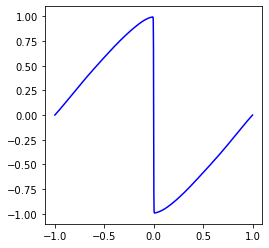

In [91]:
N = 1000
tfinal =  0.515 * np.ones(N+1)
xspace = np.linspace(lb[1], ub[1], N + 1)
Xgrid = np.vstack([tfinal.flatten(),xspace.flatten()]).T
upred = model(tf.cast(Xgrid,DTYPE))

plt.plot(xspace,upred, 'b-');
plt.axis('square')
plt.xlim([-1.1,1.1])
plt.ylim([-1.1,1.1]);

### Que se passe t'il quand on change la viscosité ?

Une viscosité de 1e-2 :

In [100]:
viscosity = tf.constant(1e-2, dtype=DTYPE)

model = PhysicsInformedNN(lb, ub, num_hidden_layers=5, num_neurons_per_layer=30, activation='tanh')
solver = PINNSolver(model, X_r)

In [101]:
t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-4,
    decay_steps=1000,
    decay_rate=0.8,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_data, u_data, N=5000)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Iteration 00000: loss = 5.74095011e-01
Iteration 00100: loss = 5.10129929e-01
Iteration 00200: loss = 4.85971093e-01
Iteration 00300: loss = 4.26429689e-01
Iteration 00400: loss = 3.15281481e-01
Iteration 00500: loss = 2.70970106e-01
Iteration 00600: loss = 2.58231550e-01
Iteration 00700: loss = 2.41546199e-01
Iteration 00800: loss = 2.08062544e-01
Iteration 00900: loss = 1.52544171e-01
Iteration 01000: loss = 1.07385769e-01
Iteration 01100: loss = 8.97525176e-02
Iteration 01200: loss = 7.87651837e-02
Iteration 01300: loss = 6.87149689e-02
Iteration 01400: loss = 5.79466000e-02
Iteration 01500: loss = 4.81788740e-02
Iteration 01600: loss = 4.05723192e-02
Iteration 01700: loss = 3.43868174e-02
Iteration 01800: loss = 2.89764255e-02
Iteration 01900: loss = 2.43677497e-02
Iteration 02000: loss = 2.04926841e-02
Iteration 02100: loss = 1.78640056e-02
Iteration 02200: loss = 1.55808274e-02
Iteration 02300: loss = 1.35618709e-02
Iteration 02400: loss = 1.17621738e-02
Iteration 02500: loss = 1

In [102]:
t0 = time()
try: 
  solver.solve_with_ScipyOptimizer(X_data, u_data)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Iteration 05000: loss = 1.41602708e-03
Iteration 05100: loss = 2.67569296e-04
Iteration 05200: loss = 1.21157609e-04
Iteration 05300: loss = 6.92177928e-05
Iteration 05400: loss = 5.21698967e-05
Iteration 05500: loss = 4.02432634e-05
Iteration 05600: loss = 2.89092150e-05
Iteration 05700: loss = 2.17705092e-05
Iteration 05800: loss = 1.76222202e-05
Iteration 05900: loss = 1.47818955e-05
Iteration 06000: loss = 1.21161374e-05
Iteration 06100: loss = 9.93844606e-06
Iteration 06200: loss = 8.44865917e-06
Iteration 06300: loss = 7.47785134e-06
Iteration 06400: loss = 6.63769970e-06
Iteration 06500: loss = 5.87556497e-06
Iteration 06600: loss = 5.01130990e-06
Iteration 06700: loss = 4.33593777e-06
Iteration 06800: loss = 3.98035945e-06
Iteration 06900: loss = 3.62481774e-06

Training time: 180.77059364318848 seconds


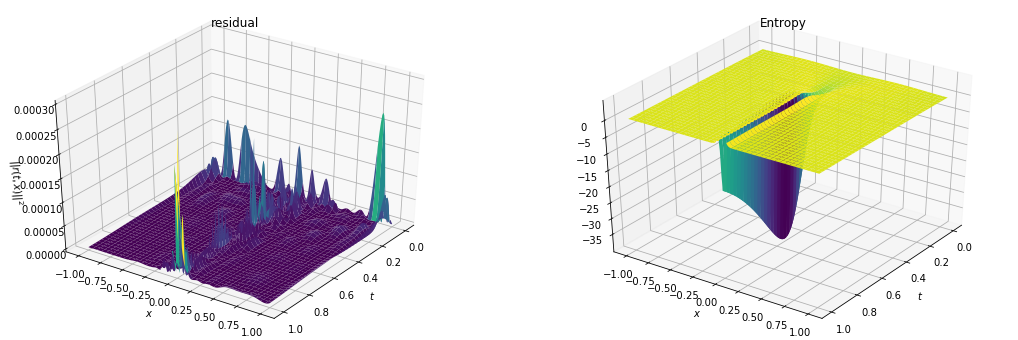

In [112]:
# compute and reshape residual for plotting
Res = get_residual(model, tf.cast(X_test,DTYPE))
R = Res.numpy().reshape(N_test+1,N_test+1)

# compute and reshape entropy
Ent = get_entropy(model,tf.cast(X_test,DTYPE))
S = Ent.numpy().reshape(N_test+1,N_test+1)

# Surface plot of residual
fig = plt.figure(figsize=(18,6))
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(T, X, np.square(R), cmap='viridis');
ax1.view_init(35,35)
ax1.set_xlabel('$t$')
ax1.set_ylabel('$x$')
ax1.set_zlabel('$||r(t,x)||^2$')
ax1.set_title('residual');

# Surface plot of entropy
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(T, X, S, cmap='viridis');
ax2.view_init(35,35)
ax2.set_xlabel('$t$')
ax2.set_ylabel('$x$')
ax2.set_zlabel('')
ax2.set_title('Entropy');

une viscosité de 1e-1:

In [113]:
viscosity = tf.constant(1e-1, dtype=DTYPE)

model = PhysicsInformedNN(lb, ub, num_hidden_layers=5, num_neurons_per_layer=30, activation='tanh')
solver = PINNSolver(model, X_r)

In [114]:
t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-4,
    decay_steps=1000,
    decay_rate=0.8,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_data, u_data, N=5000)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Iteration 00000: loss = 2.93368220e-01
Iteration 00100: loss = 2.67520398e-01
Iteration 00200: loss = 1.91923887e-01
Iteration 00300: loss = 1.48748562e-01
Iteration 00400: loss = 1.02873899e-01
Iteration 00500: loss = 8.06945935e-02
Iteration 00600: loss = 6.22418076e-02
Iteration 00700: loss = 4.76653725e-02
Iteration 00800: loss = 3.59850489e-02
Iteration 00900: loss = 2.58707758e-02
Iteration 01000: loss = 1.74627285e-02
Iteration 01100: loss = 1.26603954e-02
Iteration 01200: loss = 9.53060668e-03
Iteration 01300: loss = 7.51916831e-03
Iteration 01400: loss = 6.16280735e-03
Iteration 01500: loss = 5.18808374e-03
Iteration 01600: loss = 4.44789603e-03
Iteration 01700: loss = 3.86168412e-03
Iteration 01800: loss = 3.38214030e-03
Iteration 01900: loss = 2.97980430e-03
Iteration 02000: loss = 2.63560819e-03
Iteration 02100: loss = 2.39262055e-03
Iteration 02200: loss = 2.17221631e-03
Iteration 02300: loss = 1.97162339e-03
Iteration 02400: loss = 1.78870431e-03
Iteration 02500: loss = 1

In [115]:
t0 = time()
try: 
  solver.solve_with_ScipyOptimizer(X_data, u_data)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Iteration 05000: loss = 2.61962356e-04
Iteration 05100: loss = 3.11072872e-05
Iteration 05200: loss = 1.13869701e-05
Iteration 05300: loss = 5.46886804e-06
Iteration 05400: loss = 3.18335492e-06
Iteration 05500: loss = 2.23661254e-06

Training time: 48.78843545913696 seconds


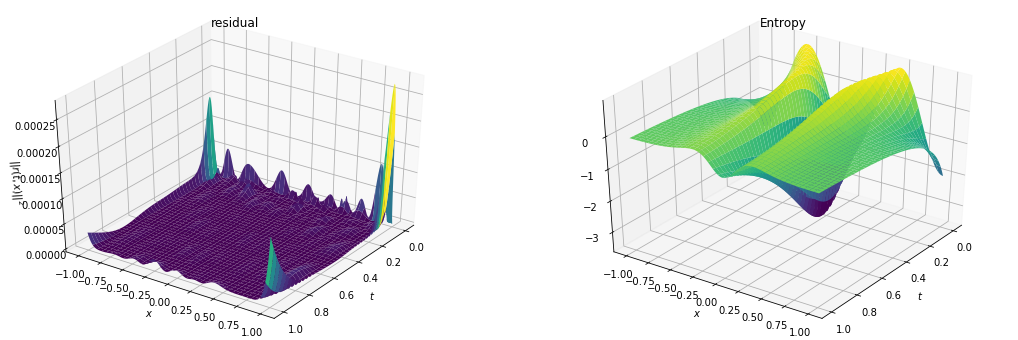

In [116]:
# compute and reshape residual for plotting
Res = get_residual(model, tf.cast(X_test,DTYPE))
R = Res.numpy().reshape(N_test+1,N_test+1)

# compute and reshape entropy
Ent = get_entropy(model,tf.cast(X_test,DTYPE))
S = Ent.numpy().reshape(N_test+1,N_test+1)

# Surface plot of residual
fig = plt.figure(figsize=(18,6))
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(T, X, np.square(R), cmap='viridis');
ax1.view_init(35,35)
ax1.set_xlabel('$t$')
ax1.set_ylabel('$x$')
ax1.set_zlabel('$||r(t,x)||^2$')
ax1.set_title('residual');

# Surface plot of entropy
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(T, X, S, cmap='viridis');
ax2.view_init(35,35)
ax2.set_xlabel('$t$')
ax2.set_ylabel('$x$')
ax2.set_zlabel('')
ax2.set_title('Entropy');